**Import Libraries**

In [5]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

In [6]:
!pip install -q imbalanced-learn

**Files in Folder**

In [7]:
import os

files_in_colab = os.listdir()

print(files_in_colab)

['.config', 'test.csv', 'train.csv', 'sample_data']


**Load The Datasets**

In [8]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (5491971, 47)
Testing dataset shape: (1176851, 47)


**Inspect the original datasets**

In [9]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

print("===== TRAINING DATA TYPES =====")
print(train_df.dtypes)

print("\n===== TESTING DATA TYPES =====")
print(test_df.dtypes)

print("===== TRAINING DATA =====")
display(train_df.head())

print("\n===== TESTING DATA =====")
display(test_df.head())

Training columns:
['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'label']

Testing columns:
['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 

,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,757.00,6.00,64.00,23.671858,23.671858,0.0,0.0,0.0,0.0,...,538.470740,944.00,8.334058e+07,9.5,41.845546,761.456760,305219.322301,0.95,141.55,DDoS-ACK_Fragmentation
1,0.000000,54.00,6.00,64.00,2.393046,2.393046,0.0,0.0,1.0,0.0,...,0.000000,54.00,8.309327e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DDoS-SYN_Flood
2,0.033982,56.78,6.11,64.64,1.192715,1.192715,0.0,0.0,0.0,0.0,...,1.727526,54.29,8.333086e+07,9.5,10.462813,2.445286,16.853118,0.19,141.55,DDoS-PSHACK_Flood
3,0.000000,0.00,47.00,64.00,9.841972,9.841972,0.0,0.0,0.0,0.0,...,0.000000,592.00,8.370278e+07,9.5,34.409301,0.000000,0.000000,0.00,141.55,Mirai-greeth_flood
4,3.944828,108.00,6.00,64.00,0.506993,0.506993,0.0,0.0,1.0,0.0,...,0.000000,54.00,8.297270e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DoS-SYN_Flood



===== TESTING DATA =====


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,5.018181,125.82,6.00,64.00,0.471037,0.471037,0.0,0.0,1.0,0.0,...,0.00000,54.00,8.336227e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DDoS-SynonymousIP_Flood
1,0.000000,0.00,47.00,64.00,4.992473,4.992473,0.0,0.0,0.0,0.0,...,0.00000,592.00,8.367746e+07,9.5,34.409301,0.000000,0.000000,0.00,141.55,Mirai-greeth_flood
2,0.000000,55.22,6.05,65.27,31.735421,31.735421,0.0,0.0,0.0,0.0,...,0.77612,55.82,8.306829e+07,9.5,10.409427,1.111579,30.890194,0.02,141.55,DDoS-TCP_Flood
3,0.008299,5213.00,17.00,64.00,19365.300906,19365.300906,0.0,0.0,0.0,0.0,...,0.00000,50.00,8.310303e+07,9.5,10.000000,0.000000,0.000000,0.00,141.55,DDoS-UDP_Flood
4,4.672666,108.00,6.00,64.00,0.428021,0.428021,0.0,0.0,0.0,0.0,...,0.00000,54.00,8.295115e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DoS-TCP_Flood


**Extract ONLY first 100,000 rows**

In [10]:
train_df = train_df.iloc[:100000].copy()
test_df = test_df.iloc[:100000].copy()

print("Training dataset after extraction:", train_df.shape)
print("Testing dataset after extraction:", test_df.shape)

Training dataset after extraction: (100000, 47)
Testing dataset after extraction: (100000, 47)


**Inspect the selected data**

In [11]:
print("Training information:")
train_df.info()

print("\nTesting information:")
test_df.info()

Training information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 47 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   flow_duration    100000 non-null  float64
 1   Header_Length    100000 non-null  float64
 2   Protocol Type    100000 non-null  float64
 3   Duration         100000 non-null  float64
 4   Rate             100000 non-null  float64
 5   Srate            100000 non-null  float64
 6   Drate            100000 non-null  float64
 7   fin_flag_number  100000 non-null  float64
 8   syn_flag_number  100000 non-null  float64
 9   rst_flag_number  100000 non-null  float64
 10  psh_flag_number  100000 non-null  float64
 11  ack_flag_number  100000 non-null  float64
 12  ece_flag_number  100000 non-null  float64
 13  cwr_flag_number  100000 non-null  float64
 14  ack_count        100000 non-null  float64
 15  syn_count        100000 non-null  float64
 16  fin_count        

**Clean column names**

In [12]:
train_df.columns = (
    train_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

test_df.columns = (
    test_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

**Check whether both datasets have the same columns**

In [13]:
print("Same columns?",
      list(train_df.columns) == list(test_df.columns))

print("Columns only in training:")
print(set(train_df.columns) - set(test_df.columns))

print("\nColumns only in testing:")
print(set(test_df.columns) - set(train_df.columns))

Same columns? True
Columns only in training:
set()

Columns only in testing:
set()


**Check missing values**

In [14]:
print("Missing values in training:")
print(train_df.isnull().sum())

print("\nMissing values in testing:")
print(test_df.isnull().sum())

Missing values in training:
flow_duration      0
header_length      0
protocol_type      0
duration           0
rate               0
srate              0
drate              0
fin_flag_number    0
syn_flag_number    0
rst_flag_number    0
psh_flag_number    0
ack_flag_number    0
ece_flag_number    0
cwr_flag_number    0
ack_count          0
syn_count          0
fin_count          0
urg_count          0
rst_count          0
http               0
https              0
dns                0
telnet             0
smtp               0
ssh                0
irc                0
tcp                0
udp                0
dhcp               0
arp                0
icmp               0
ipv                0
llc                0
tot_sum            0
min                0
max                0
avg                0
std                0
tot_size           0
iat                0
number             0
magnitue           0
radius             0
covariance         0
variance           0
weight             0
label 

**Fill null entries**

In [15]:
numeric_columns = train_df.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_columns = train_df.select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['flow_duration', 'header_length', 'protocol_type', 'duration', 'rate', 'srate', 'drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'http', 'https', 'dns', 'telnet', 'smtp', 'ssh', 'irc', 'tcp', 'udp', 'dhcp', 'arp', 'icmp', 'ipv', 'llc', 'tot_sum', 'min', 'max', 'avg', 'std', 'tot_size', 'iat', 'number', 'magnitue', 'radius', 'covariance', 'variance', 'weight']

Categorical columns:
['label']


In [16]:
for column in numeric_columns:
    median_value = train_df[column].median()

    train_df[column] = train_df[column].fillna(median_value)

    if column in test_df.columns:
        test_df[column] = test_df[column].fillna(median_value)

In [17]:
for column in categorical_columns:
    mode_value = train_df[column].mode()[0]

    train_df[column] = train_df[column].fillna(mode_value)

    if column in test_df.columns:
        test_df[column] = test_df[column].fillna(mode_value)

In [18]:
print("Remaining missing values in training:",
      train_df.isnull().sum().sum())

print("Remaining missing values in testing:",
      test_df.isnull().sum().sum())

Remaining missing values in training: 0
Remaining missing values in testing: 0


**Identify the target column**

In [19]:
print("All columns:")
for i, column in enumerate(train_df.columns):
    print(i, ":", column)

All columns:
0 : flow_duration
1 : header_length
2 : protocol_type
3 : duration
4 : rate
5 : srate
6 : drate
7 : fin_flag_number
8 : syn_flag_number
9 : rst_flag_number
10 : psh_flag_number
11 : ack_flag_number
12 : ece_flag_number
13 : cwr_flag_number
14 : ack_count
15 : syn_count
16 : fin_count
17 : urg_count
18 : rst_count
19 : http
20 : https
21 : dns
22 : telnet
23 : smtp
24 : ssh
25 : irc
26 : tcp
27 : udp
28 : dhcp
29 : arp
30 : icmp
31 : ipv
32 : llc
33 : tot_sum
34 : min
35 : max
36 : avg
37 : std
38 : tot_size
39 : iat
40 : number
41 : magnitue
42 : radius
43 : covariance
44 : variance
45 : weight
46 : label


In [20]:
target_column = "label"
print("Target column:", target_column)

print("\nTarget values:")
print(train_df[target_column].value_counts())

print("\nTarget distribution (%):")
print(
    train_df[target_column]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target column: label

Target values:
label
DDoS-ICMP_Flood            15633
DDoS-UDP_Flood             11505
DDoS-TCP_Flood              9621
DDoS-PSHACK_Flood           8752
DDoS-RSTFINFlood            8704
DDoS-SYN_Flood              8675
DDoS-SynonymousIP_Flood     7665
DoS-UDP_Flood               7178
DoS-TCP_Flood               5747
DoS-SYN_Flood               4267
BenignTraffic               2267
Mirai-greeth_flood          2111
Mirai-udpplain              1891
Mirai-greip_flood           1629
DDoS-ICMP_Fragmentation      971
MITM-ArpSpoofing             655
DDoS-UDP_Fragmentation       600
DDoS-ACK_Fragmentation       591
DNS_Spoofing                 401
Recon-HostDiscovery          281
Recon-OSScan                 218
Recon-PortScan               184
DoS-HTTP_Flood               165
VulnerabilityScan             80
DDoS-HTTP_Flood               79
DDoS-SlowLoris                38
DictionaryBruteForce          34
SqlInjection                  12
Backdoor_Malware               9


**Visualize target distribution(Before SMOTE)**

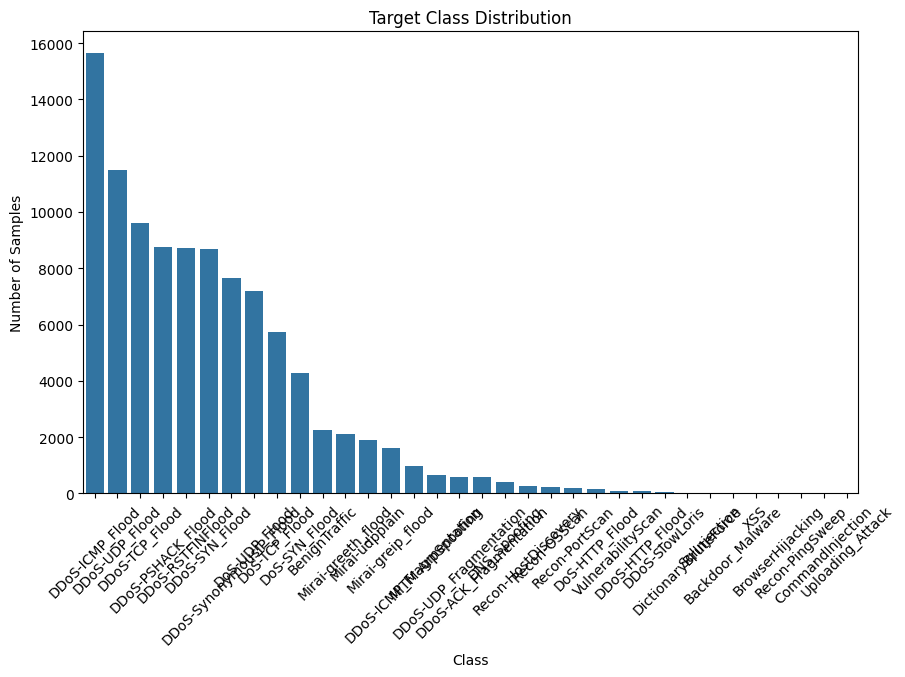

In [21]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=train_df,
    x=target_column,
    order=train_df[target_column].value_counts().index
)

plt.title("Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.show()

**Binary classification**

In [22]:

train_df["binary_target"] = (
    train_df[target_column]
    .astype(str)
    .str.strip()
    .str.lower()
    .apply(lambda x: 0 if x == "benigntraffic" else 1)
)

test_df["binary_target"] = (
    test_df[target_column]
    .astype(str)
    .str.strip()
    .str.lower()
    .apply(lambda x: 0 if x == "benigntraffic" else 1)
)

print("Training target distribution:")
print(train_df["binary_target"].value_counts())

print("\nTesting target distribution:")
print(test_df["binary_target"].value_counts())


Training target distribution:
binary_target
1    97733
0     2267
Name: count, dtype: int64

Testing target distribution:
binary_target
1    97630
0     2370
Name: count, dtype: int64


In [23]:
print("Target column:", target_column)
print("Sample labels:")
print(train_df[target_column].head(10).tolist())

print("\nUnique class count:")
print(train_df[target_column].nunique())

Target column: label
Sample labels:
['DDoS-ACK_Fragmentation', 'DDoS-SYN_Flood', 'DDoS-PSHACK_Flood', 'Mirai-greeth_flood', 'DoS-SYN_Flood', 'DDoS-ICMP_Flood', 'DDoS-ICMP_Flood', 'DDoS-TCP_Flood', 'DDoS-SYN_Flood', 'DDoS-ICMP_Flood']

Unique class count:
34


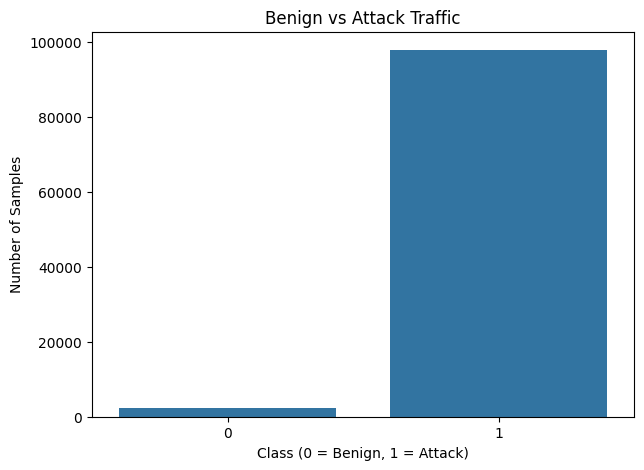

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="binary_target"
)

plt.title("Benign vs Attack Traffic")
plt.xlabel("Class (0 = Benign, 1 = Attack)")
plt.ylabel("Number of Samples")

plt.show()

**Remove ID columns**

In [25]:
id_columns = []

for column in train_df.columns:
    if (
        column.lower() == "id"
        or column.lower().endswith("_id")
        or column.lower().startswith("unnamed")
        or column.lower() == "index"
    ):
        id_columns.append(column)

print("Potential ID columns:")
print(id_columns)

train_df.drop(columns=id_columns, inplace=True, errors="ignore")
test_df.drop(columns=id_columns, inplace=True, errors="ignore")

Potential ID columns:
[]


**Remove the original target**

In [26]:
train_df.drop(columns=[target_column], inplace=True)
test_df.drop(columns=[target_column], inplace=True)

**Separate X and y**

In [27]:
X_train = train_df.drop(columns=["binary_target"])
y_train = train_df["binary_target"]

X_test = test_df.drop(columns=["binary_target"])
y_test = test_df["binary_target"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (100000, 46)
y_train: (100000,)
X_test: (100000, 46)
y_test: (100000,)


**Classify numerical and categorical columns**

In [28]:
numeric_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("Number of numerical features:",
      len(numeric_features))

print("Number of categorical features:",
      len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 46
Number of categorical features: 0

Numerical features:
['flow_duration', 'header_length', 'protocol_type', 'duration', 'rate', 'srate', 'drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'http', 'https', 'dns', 'telnet', 'smtp', 'ssh', 'irc', 'tcp', 'udp', 'dhcp', 'arp', 'icmp', 'ipv', 'llc', 'tot_sum', 'min', 'max', 'avg', 'std', 'tot_size', 'iat', 'number', 'magnitue', 'radius', 'covariance', 'variance', 'weight']

Categorical features:
[]


**Convert categorical features**

In [29]:
from sklearn.preprocessing import OrdinalEncoder

if len(categorical_features) > 0:

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    X_train[categorical_features] = encoder.fit_transform(
        X_train[categorical_features]
    )

    X_test[categorical_features] = encoder.transform(
        X_test[categorical_features]
    )

**Make sure all values are numeric**

In [30]:
print("Non-numeric training columns:")
print(
    X_train.select_dtypes(exclude=np.number).columns.tolist()
)

print("\nNon-numeric testing columns:")
print(
    X_test.select_dtypes(exclude=np.number).columns.tolist()
)

Non-numeric training columns:
[]

Non-numeric testing columns:
[]


**Handle infinite values**

In [31]:
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

for column in X_train.columns:

    median_value = X_train[column].median()

    X_train[column] = X_train[column].fillna(median_value)
    X_test[column] = X_test[column].fillna(median_value)

print("NaN in X_train:", X_train.isnull().sum().sum())
print("NaN in X_test:", X_test.isnull().sum().sum())

NaN in X_train: 0
NaN in X_test: 0


**Check class balance before training**

In [32]:
print("Training classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

print("\nTraining percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting percentage:")
print(y_test.value_counts(normalize=True) * 100)

Training classes:
binary_target
1    97733
0     2267
Name: count, dtype: int64

Testing classes:
binary_target
1    97630
0     2370
Name: count, dtype: int64

Training percentage:
binary_target
1    97.733
0     2.267
Name: proportion, dtype: float64

Testing percentage:
binary_target
1    97.63
0     2.37
Name: proportion, dtype: float64


**Multiclass SMOTE**

In [33]:
import pandas as pd
import numpy as np

# Reload original data into separate DataFrames
train_multi_df = pd.read_csv("train.csv").iloc[:100000].copy()
test_multi_df = pd.read_csv("test.csv").iloc[:100000].copy()

# Clean column names
train_multi_df.columns = (
    train_multi_df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

test_multi_df.columns = (
    test_multi_df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Check whether the original label column exists
print("Training columns:", train_multi_df.columns.tolist())
print("Test columns:", test_multi_df.columns.tolist())

# Original multiclass targets: preserve all attack names
y_train_multi = train_multi_df["label"].astype(str).str.strip()
y_test_multi = test_multi_df["label"].astype(str).str.strip()

# Features: remove only the original label column
X_train_multi = train_multi_df.drop(columns=["label"]).copy()
X_test_multi = test_multi_df.drop(columns=["label"]).copy()

# Replace infinite values and handle missing values
X_train_multi = X_train_multi.replace([np.inf, -np.inf], np.nan)
X_test_multi = X_test_multi.replace([np.inf, -np.inf], np.nan)

# Calculate medians using training data only
medians = X_train_multi.median()

X_train_multi = X_train_multi.fillna(medians)
X_test_multi = X_test_multi.fillna(medians)

# Display results
print("\nNumber of original training classes:", y_train_multi.nunique())
print("Number of test classes:", y_test_multi.nunique())
print("Training features:", X_train_multi.shape)
print("Training labels:", y_train_multi.shape)

print("\nOriginal multiclass distribution:")
print(y_train_multi.value_counts())

Training columns: ['flow_duration', 'header_length', 'protocol_type', 'duration', 'rate', 'srate', 'drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'http', 'https', 'dns', 'telnet', 'smtp', 'ssh', 'irc', 'tcp', 'udp', 'dhcp', 'arp', 'icmp', 'ipv', 'llc', 'tot_sum', 'min', 'max', 'avg', 'std', 'tot_size', 'iat', 'number', 'magnitue', 'radius', 'covariance', 'variance', 'weight', 'label']
Test columns: ['flow_duration', 'header_length', 'protocol_type', 'duration', 'rate', 'srate', 'drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'http', 'https', 'dns', 'telnet', 'smtp', 'ssh', 'irc', 'tcp', 'udp', 'dhcp', 'arp', 'icmp', 'ipv', 'llc', 'tot_sum', 'min', 'max', 'avg', 'std', 'tot

In [34]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to all 34 original classes
smote_multi = SMOTE(
    random_state=42,
    k_neighbors=3
)

X_train_multi_smote, y_train_multi_smote = smote_multi.fit_resample(
    X_train_multi,
    y_train_multi
)

print("Classes before SMOTE:", y_train_multi.nunique())
print("Classes after SMOTE:", y_train_multi_smote.nunique())

print("\nSamples before SMOTE:", len(y_train_multi))
print("Samples after SMOTE:", len(y_train_multi_smote))

print("\nClass distribution after SMOTE:")
print(y_train_multi_smote.value_counts().sort_index())

Classes before SMOTE: 34
Classes after SMOTE: 34

Samples before SMOTE: 100000
Samples after SMOTE: 531522

Class distribution after SMOTE:
label
Backdoor_Malware           15633
BenignTraffic              15633
BrowserHijacking           15633
CommandInjection           15633
DDoS-ACK_Fragmentation     15633
DDoS-HTTP_Flood            15633
DDoS-ICMP_Flood            15633
DDoS-ICMP_Fragmentation    15633
DDoS-PSHACK_Flood          15633
DDoS-RSTFINFlood           15633
DDoS-SYN_Flood             15633
DDoS-SlowLoris             15633
DDoS-SynonymousIP_Flood    15633
DDoS-TCP_Flood             15633
DDoS-UDP_Flood             15633
DDoS-UDP_Fragmentation     15633
DNS_Spoofing               15633
DictionaryBruteForce       15633
DoS-HTTP_Flood             15633
DoS-SYN_Flood              15633
DoS-TCP_Flood              15633
DoS-UDP_Flood              15633
MITM-ArpSpoofing           15633
Mirai-greeth_flood         15633
Mirai-greip_flood          15633
Mirai-udpplain             15

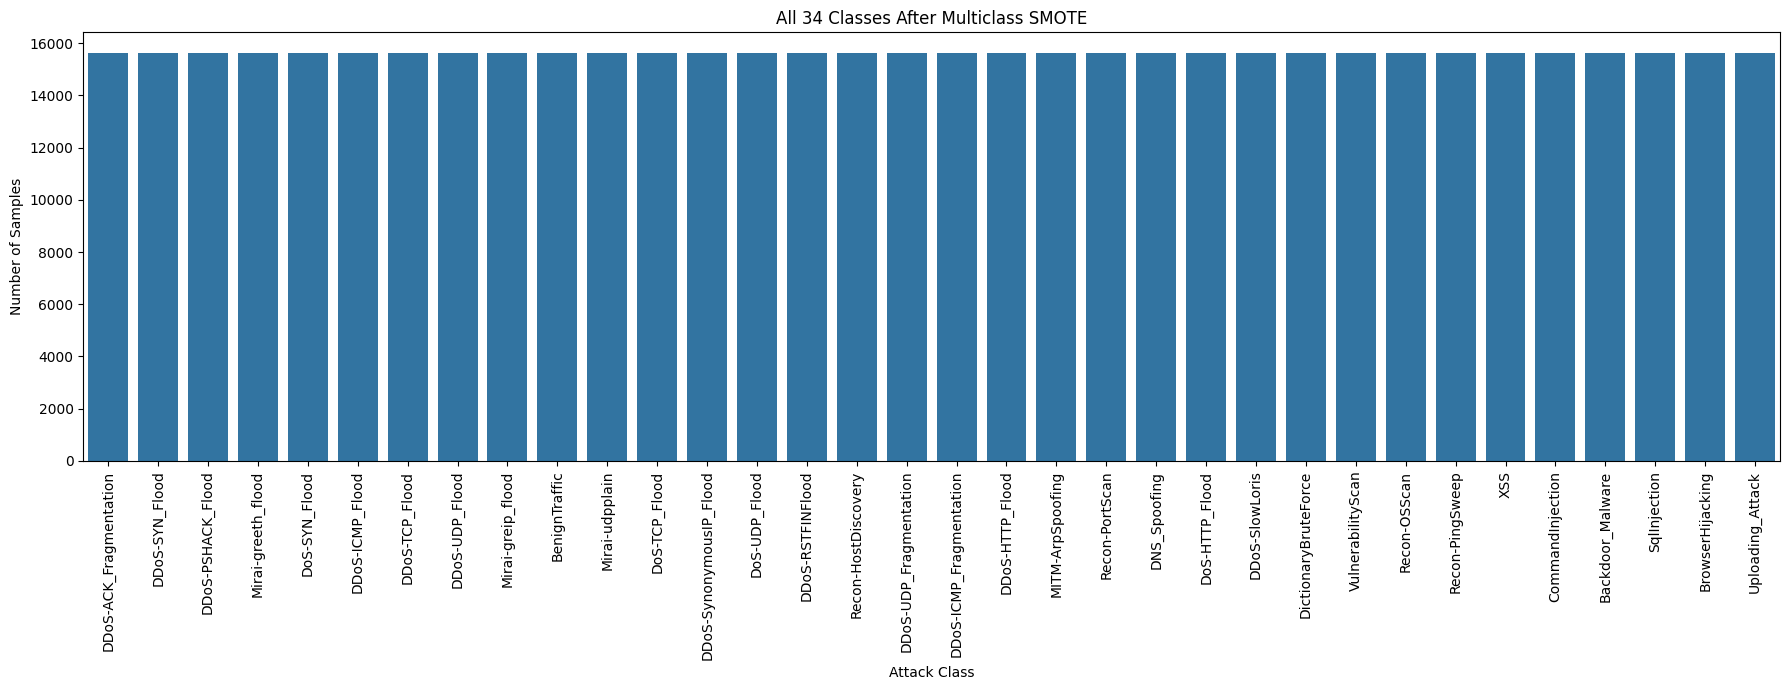

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

after_counts = y_train_multi_smote.value_counts().sort_values(
    ascending=False
)

plt.figure(figsize=(18, 7))

sns.barplot(
    x=after_counts.index,
    y=after_counts.values
)

plt.title("All 34 Classes After Multiclass SMOTE")
plt.xlabel("Attack Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

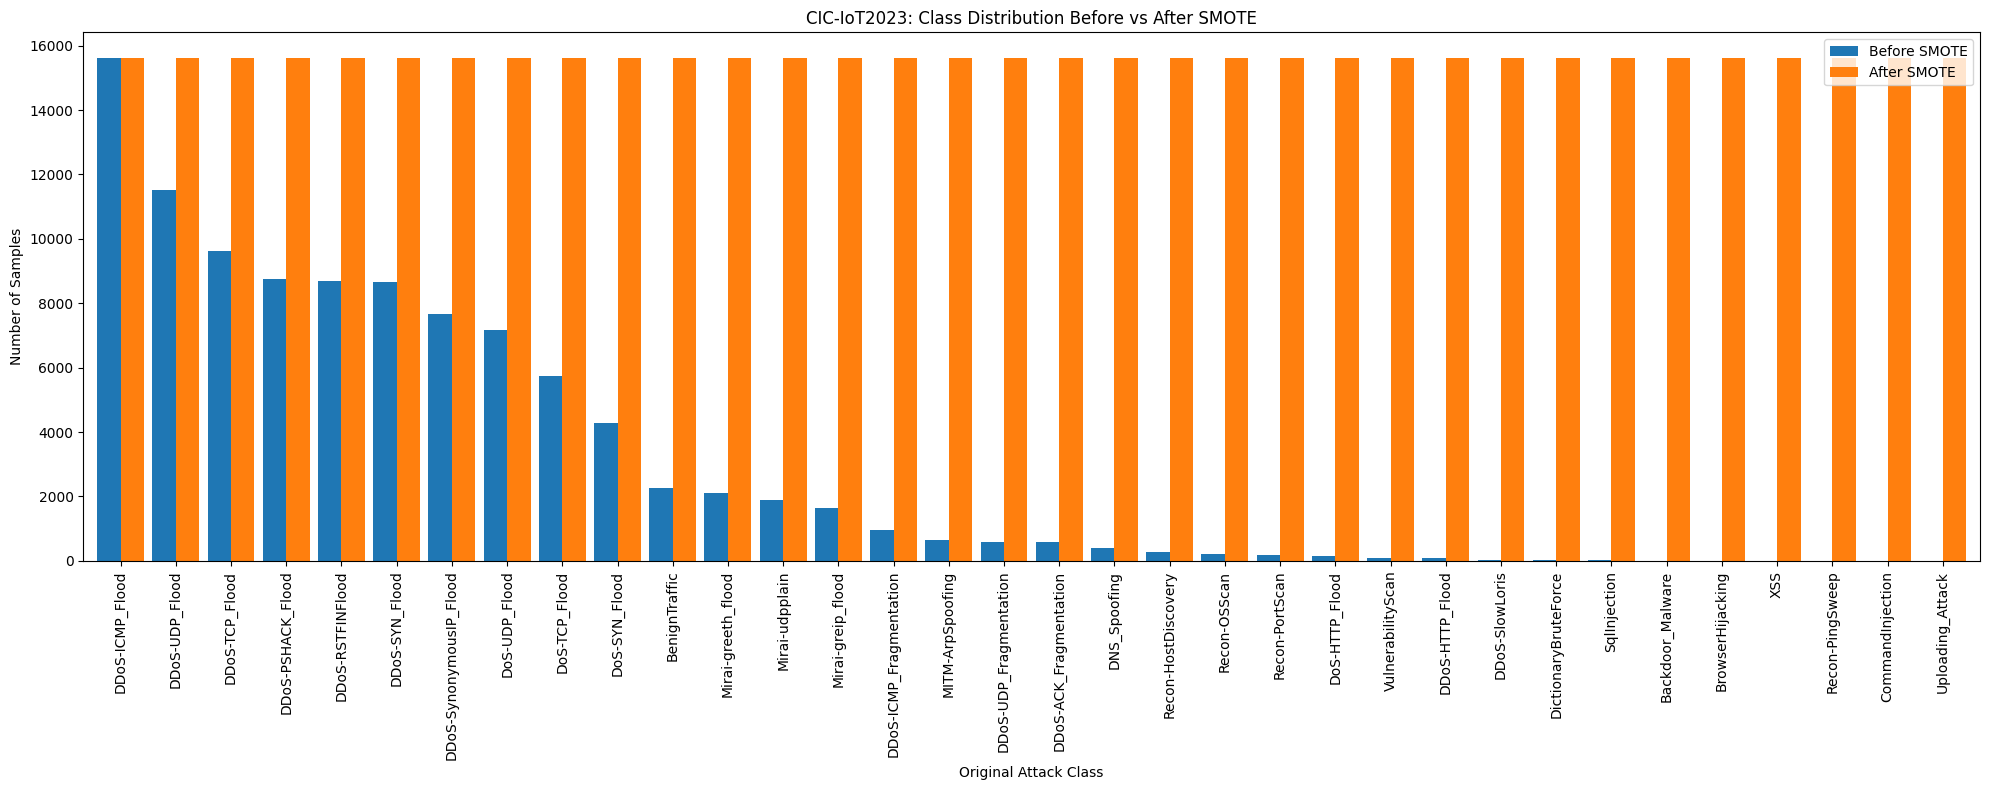

In [36]:
comparison = pd.DataFrame({
    "Before SMOTE": y_train_multi.value_counts(),
    "After SMOTE": y_train_multi_smote.value_counts()
}).fillna(0)

comparison = comparison.sort_values(
    "Before SMOTE",
    ascending=False
)

comparison.plot(
    kind="bar",
    figsize=(20, 8),
    width=0.85
)

plt.title("CIC-IoT2023: Class Distribution Before vs After SMOTE")
plt.xlabel("Original Attack Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

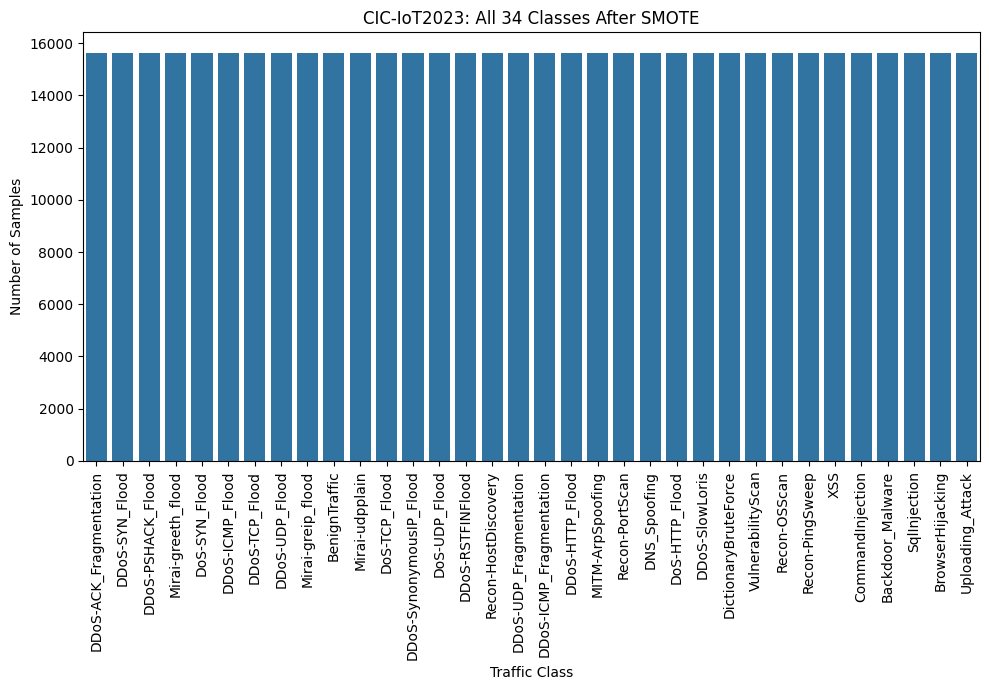

In [37]:

after_counts = y_train_multi_smote.value_counts().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=after_counts.index,
    y=after_counts.values
)

plt.title("CIC-IoT2023: All 34 Classes After SMOTE")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


**Binary SMOTE — Benign vs. Attack**

In [38]:
from imblearn.over_sampling import SMOTE

smote_binary = SMOTE(random_state=42)

X_train_binary_smote, y_train_binary_smote = (
    smote_binary.fit_resample(X_train, y_train)
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_binary_smote.value_counts())

print("\nNew training shape:", X_train_binary_smote.shape)

Before SMOTE:
binary_target
1    97733
0     2267
Name: count, dtype: int64

After SMOTE:
binary_target
1    97733
0    97733
Name: count, dtype: int64

New training shape: (195466, 46)


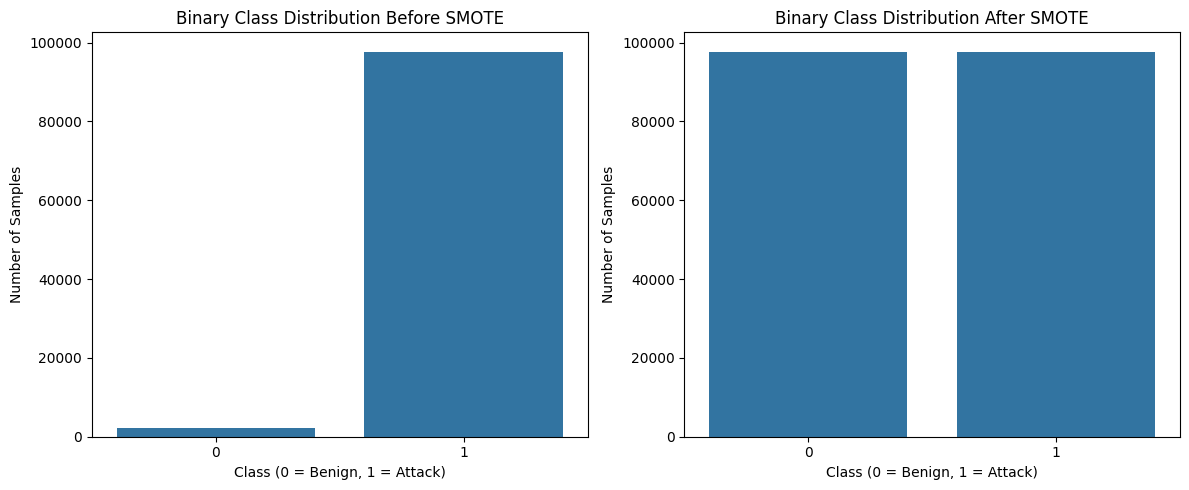

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

before = y_train.value_counts().reindex([0, 1], fill_value=0)
after = y_train_binary_smote.value_counts().reindex([0, 1], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x=before.index.astype(str), y=before.values, ax=axes[0])
axes[0].set_title("Binary Class Distribution Before SMOTE")
axes[0].set_xlabel("Class (0 = Benign, 1 = Attack)")
axes[0].set_ylabel("Number of Samples")

sns.barplot(x=after.index.astype(str), y=after.values, ax=axes[1])
axes[1].set_title("Binary Class Distribution After SMOTE")
axes[1].set_xlabel("Class (0 = Benign, 1 = Attack)")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [40]:
from sklearn.preprocessing import LabelEncoder

label_encoder_multi = LabelEncoder()

y_train_multi_encoded = label_encoder_multi.fit_transform(
    y_train_multi_smote
)

y_test_multi_encoded = label_encoder_multi.transform(
    y_test_multi
)

print("Number of classes:", len(label_encoder_multi.classes_))
print("Encoded training labels:", y_train_multi_encoded.shape)
print("Encoded test labels:", y_test_multi_encoded.shape)

Number of classes: 34
Encoded training labels: (531522,)
Encoded test labels: (100000,)


**Train Random Forest**

In [41]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import time

# Create Random Forest model
rf_multi = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_multi.fit(
    X_train_multi_smote,
    y_train_multi_encoded
)

rf_train_time = time.time() - start_time


In [42]:
# Make predictions on the original test set
rf_multi_predictions = rf_multi.predict(X_test_multi)

**Evaluate Random Forest**

In [43]:
# Evaluate the model
print("RANDOM FOREST - MULTICLASS RESULTS")
print("Accuracy:", accuracy_score(
    y_test_multi_encoded,
    rf_multi_predictions
))
print("Training time:", round(rf_train_time, 2), "seconds")

RANDOM FOREST - MULTICLASS RESULTS
Accuracy: 0.9899
Training time: 291.08 seconds


**Classification report**

In [44]:
print("\nClassification Report:")
print(classification_report(
    y_test_multi_encoded,
    rf_multi_predictions,
    labels=range(len(label_encoder_multi.classes_)),
    target_names=label_encoder_multi.classes_,
    zero_division=0
))


Classification Report:
                         precision    recall  f1-score   support

       Backdoor_Malware       0.00      0.00      0.00        10
          BenignTraffic       0.86      0.94      0.90      2370
       BrowserHijacking       1.00      0.29      0.44         7
       CommandInjection       1.00      0.25      0.40        12
 DDoS-ACK_Fragmentation       0.99      0.99      0.99       589
        DDoS-HTTP_Flood       0.96      0.91      0.93        55
        DDoS-ICMP_Flood       1.00      1.00      1.00     15467
DDoS-ICMP_Fragmentation       0.98      0.99      0.99      1018
      DDoS-PSHACK_Flood       1.00      1.00      1.00      8695
       DDoS-RSTFINFlood       1.00      1.00      1.00      8575
         DDoS-SYN_Flood       1.00      1.00      1.00      8795
         DDoS-SlowLoris       0.86      0.84      0.85        51
DDoS-SynonymousIP_Flood       1.00      1.00      1.00      7710
         DDoS-TCP_Flood       1.00      1.00      1.00      9578


**Random Forest confusion matrix**

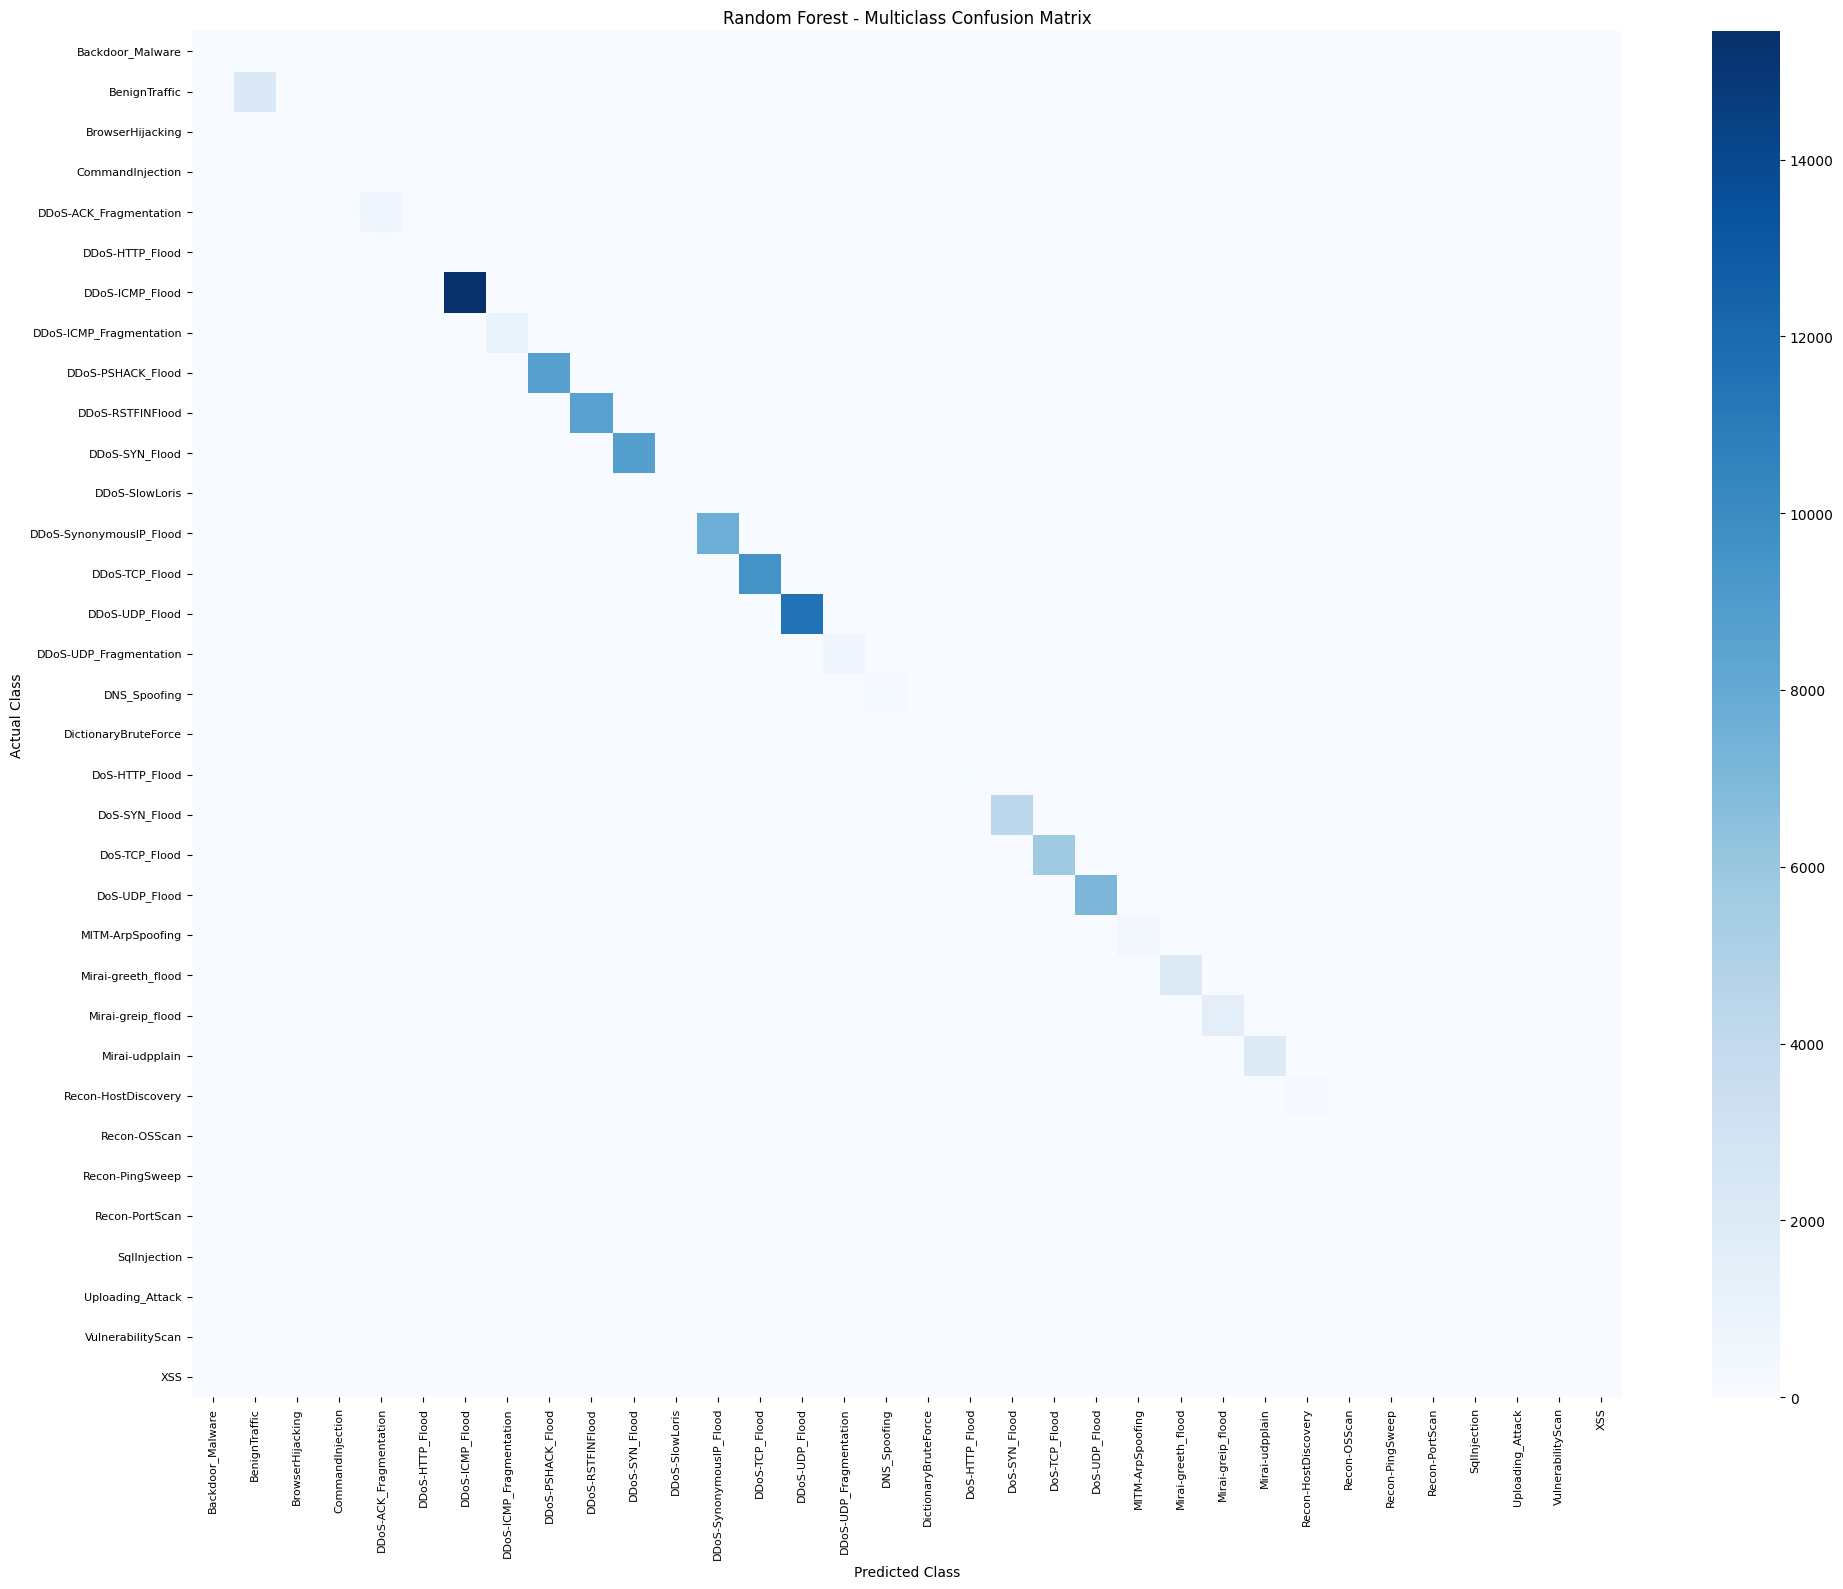

In [45]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
rf_confusion_matrix = confusion_matrix(
    y_test_multi_encoded,
    rf_multi_predictions,
    labels=range(len(label_encoder_multi.classes_))
)

# Visualize confusion matrix
plt.figure(figsize=(20, 16))

sns.heatmap(
    rf_confusion_matrix,
    annot=False,
    cmap="Blues",
    xticklabels=label_encoder_multi.classes_,
    yticklabels=label_encoder_multi.classes_
)

plt.title("Random Forest - Multiclass Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()


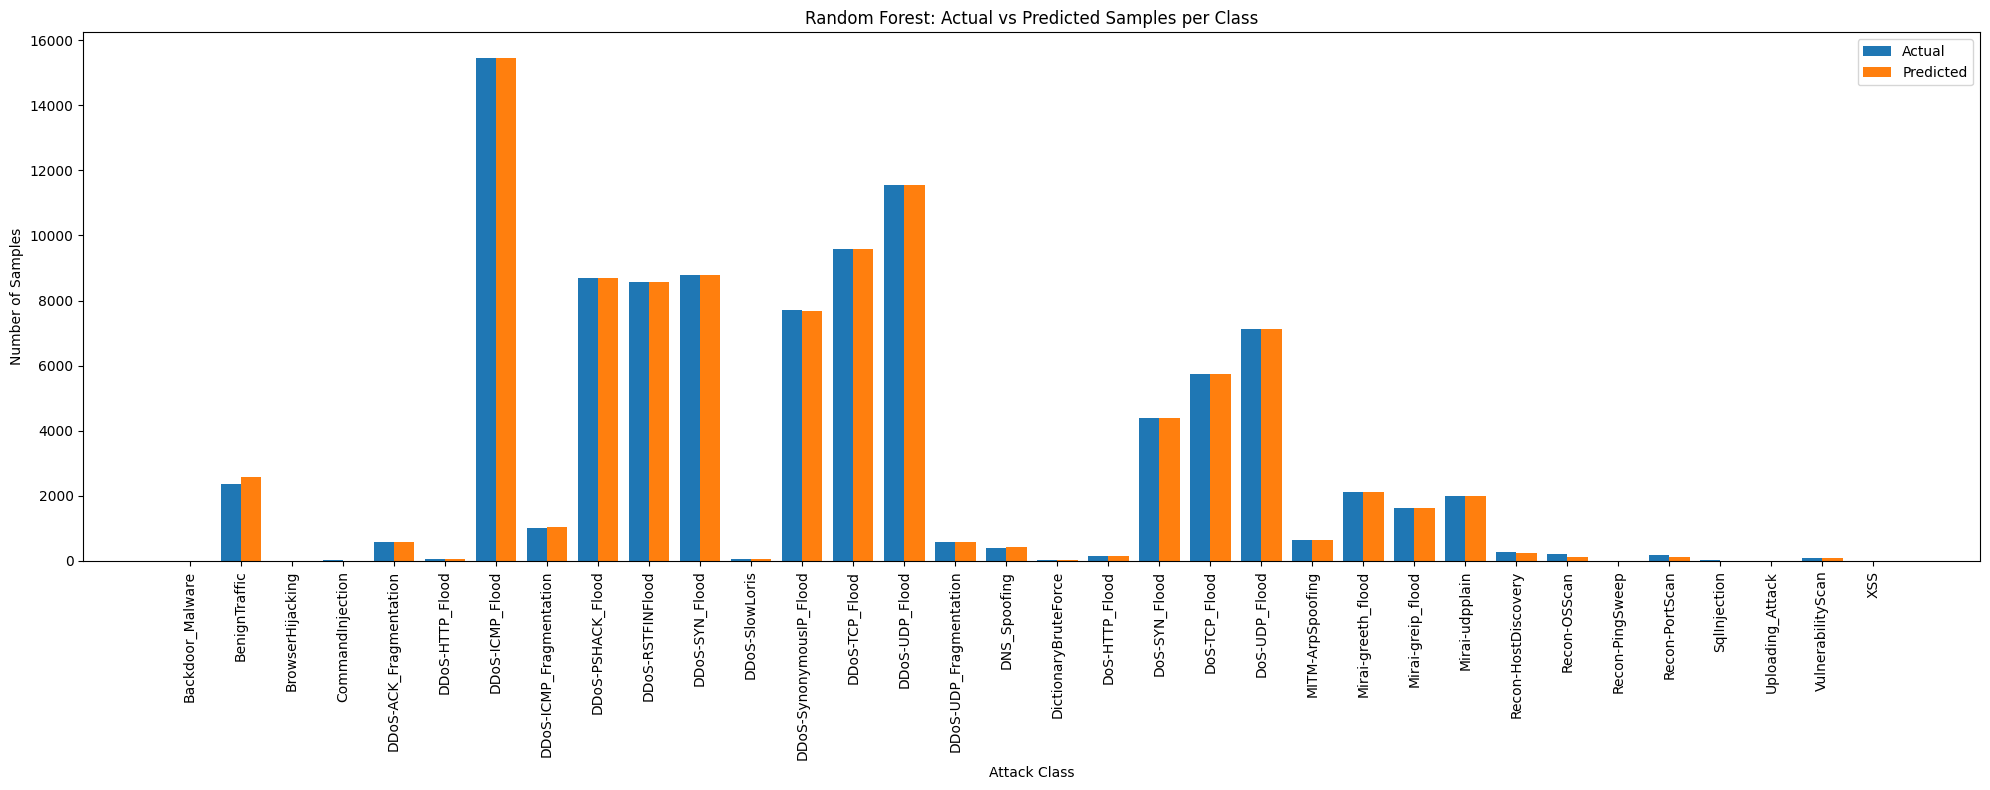

In [46]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Count actual and predicted samples for each class
actual_counts = np.bincount(
    y_test_multi_encoded,
    minlength=len(label_encoder_multi.classes_)
)

predicted_counts = np.bincount(
    rf_multi_predictions,
    minlength=len(label_encoder_multi.classes_)
)

comparison_df = pd.DataFrame({
    "Attack Class": label_encoder_multi.classes_,
    "Actual Samples": actual_counts,
    "Predicted Samples": predicted_counts
})

# Create grouped bar chart
x = np.arange(len(comparison_df))
width = 0.4

plt.figure(figsize=(20, 8))

plt.bar(
    x - width / 2,
    comparison_df["Actual Samples"],
    width,
    label="Actual"
)

plt.bar(
    x + width / 2,
    comparison_df["Predicted Samples"],
    width,
    label="Predicted"
)

plt.title("Random Forest: Actual vs Predicted Samples per Class")
plt.xlabel("Attack Class")
plt.ylabel("Number of Samples")
plt.xticks(x, comparison_df["Attack Class"], rotation=90)
plt.legend()
plt.tight_layout()
plt.show()


In [47]:

import pandas as pd
from sklearn.metrics import classification_report

# Generate classification report as a dictionary
rf_report = classification_report(
    y_test_multi_encoded,
    rf_multi_predictions,
    labels=range(len(label_encoder_multi.classes_)),
    target_names=label_encoder_multi.classes_,
    output_dict=True,
    zero_division=0
)

# Convert report into a DataFrame
rf_report_df = pd.DataFrame(rf_report).transpose()

# Display the classification report as a table
print("RANDOM FOREST - MULTICLASS CLASSIFICATION REPORT")
display(rf_report_df.round(4))


RANDOM FOREST - MULTICLASS CLASSIFICATION REPORT


,precision,recall,f1-score,support
Backdoor_Malware,0.0000,0.0000,0.0000,10.0000
BenignTraffic,0.8624,0.9418,0.9004,2370.0000
BrowserHijacking,1.0000,0.2857,0.4444,7.0000
CommandInjection,1.0000,0.2500,0.4000,12.0000
DDoS-ACK_Fragmentation,0.9932,0.9881,0.9906,589.0000
DDoS-HTTP_Flood,0.9615,0.9091,0.9346,55.0000
DDoS-ICMP_Flood,1.0000,0.9989,0.9995,15467.0000
DDoS-ICMP_Fragmentation,0.9824,0.9892,0.9858,1018.0000
DDoS-PSHACK_Flood,0.9998,0.9992,0.9995,8695.0000
DDoS-RSTFINFlood,1.0000,0.9997,0.9998,8575.0000


**Train XGBoost**

In [48]:

from xgboost import XGBClassifier
import time
from sklearn.metrics import accuracy_score

# Create XGBoost model
xgb_multi = XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder_multi.classes_),
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1
)

# Train model
start_time = time.time()

xgb_multi.fit(
    X_train_multi_smote,
    y_train_multi_encoded
)

xgb_train_time = time.time() - start_time

In [49]:
# Predict using the original test data
xgb_multi_predictions = xgb_multi.predict(X_test_multi)

print("XGBOOST - MULTICLASS RESULTS")
print("Accuracy:", accuracy_score(
    y_test_multi_encoded,
    xgb_multi_predictions
))
print("Training time:", round(xgb_train_time, 2), "seconds")


XGBOOST - MULTICLASS RESULTS
Accuracy: 0.99214
Training time: 360.88 seconds


**Evaluate XGBoost**

In [50]:
xgb_accuracy = accuracy_score(y_test, xgb_multi_predictions)
xgb_precision = precision_score(
    y_test,
    xgb_multi_predictions,
    average="weighted"
)

xgb_recall = recall_score(
    y_test,
    xgb_multi_predictions,
    average="weighted"
)

xgb_f1 = f1_score(
    y_test,
    xgb_multi_predictions,
    average="weighted"
)

print("===== XGBOOST =====")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)

===== XGBOOST =====
Accuracy : 0.00137
Precision: 0.05913045977011494
Recall   : 0.00137
F1 Score : 0.002677954190525768


In [51]:
import pandas as pd
from sklearn.metrics import classification_report

xgb_report = classification_report(
    y_test_multi_encoded,
    xgb_multi_predictions,
    labels=range(len(label_encoder_multi.classes_)),
    target_names=label_encoder_multi.classes_,
    output_dict=True,
    zero_division=0
)

xgb_report_df = pd.DataFrame(xgb_report).transpose()

print("XGBOOST - MULTICLASS CLASSIFICATION REPORT")
display(xgb_report_df.round(4))


XGBOOST - MULTICLASS CLASSIFICATION REPORT


,precision,recall,f1-score,support
Backdoor_Malware,1.0000,0.5000,0.6667,10.0000
BenignTraffic,0.9394,0.8966,0.9175,2370.0000
BrowserHijacking,0.5556,0.7143,0.6250,7.0000
CommandInjection,1.0000,0.3333,0.5000,12.0000
DDoS-ACK_Fragmentation,1.0000,0.9915,0.9957,589.0000
DDoS-HTTP_Flood,0.9434,0.9091,0.9259,55.0000
DDoS-ICMP_Flood,1.0000,0.9997,0.9999,15467.0000
DDoS-ICMP_Fragmentation,0.9990,0.9971,0.9980,1018.0000
DDoS-PSHACK_Flood,1.0000,0.9997,0.9998,8695.0000
DDoS-RSTFINFlood,0.9997,0.9998,0.9997,8575.0000


**XGBoost confusion matrix**

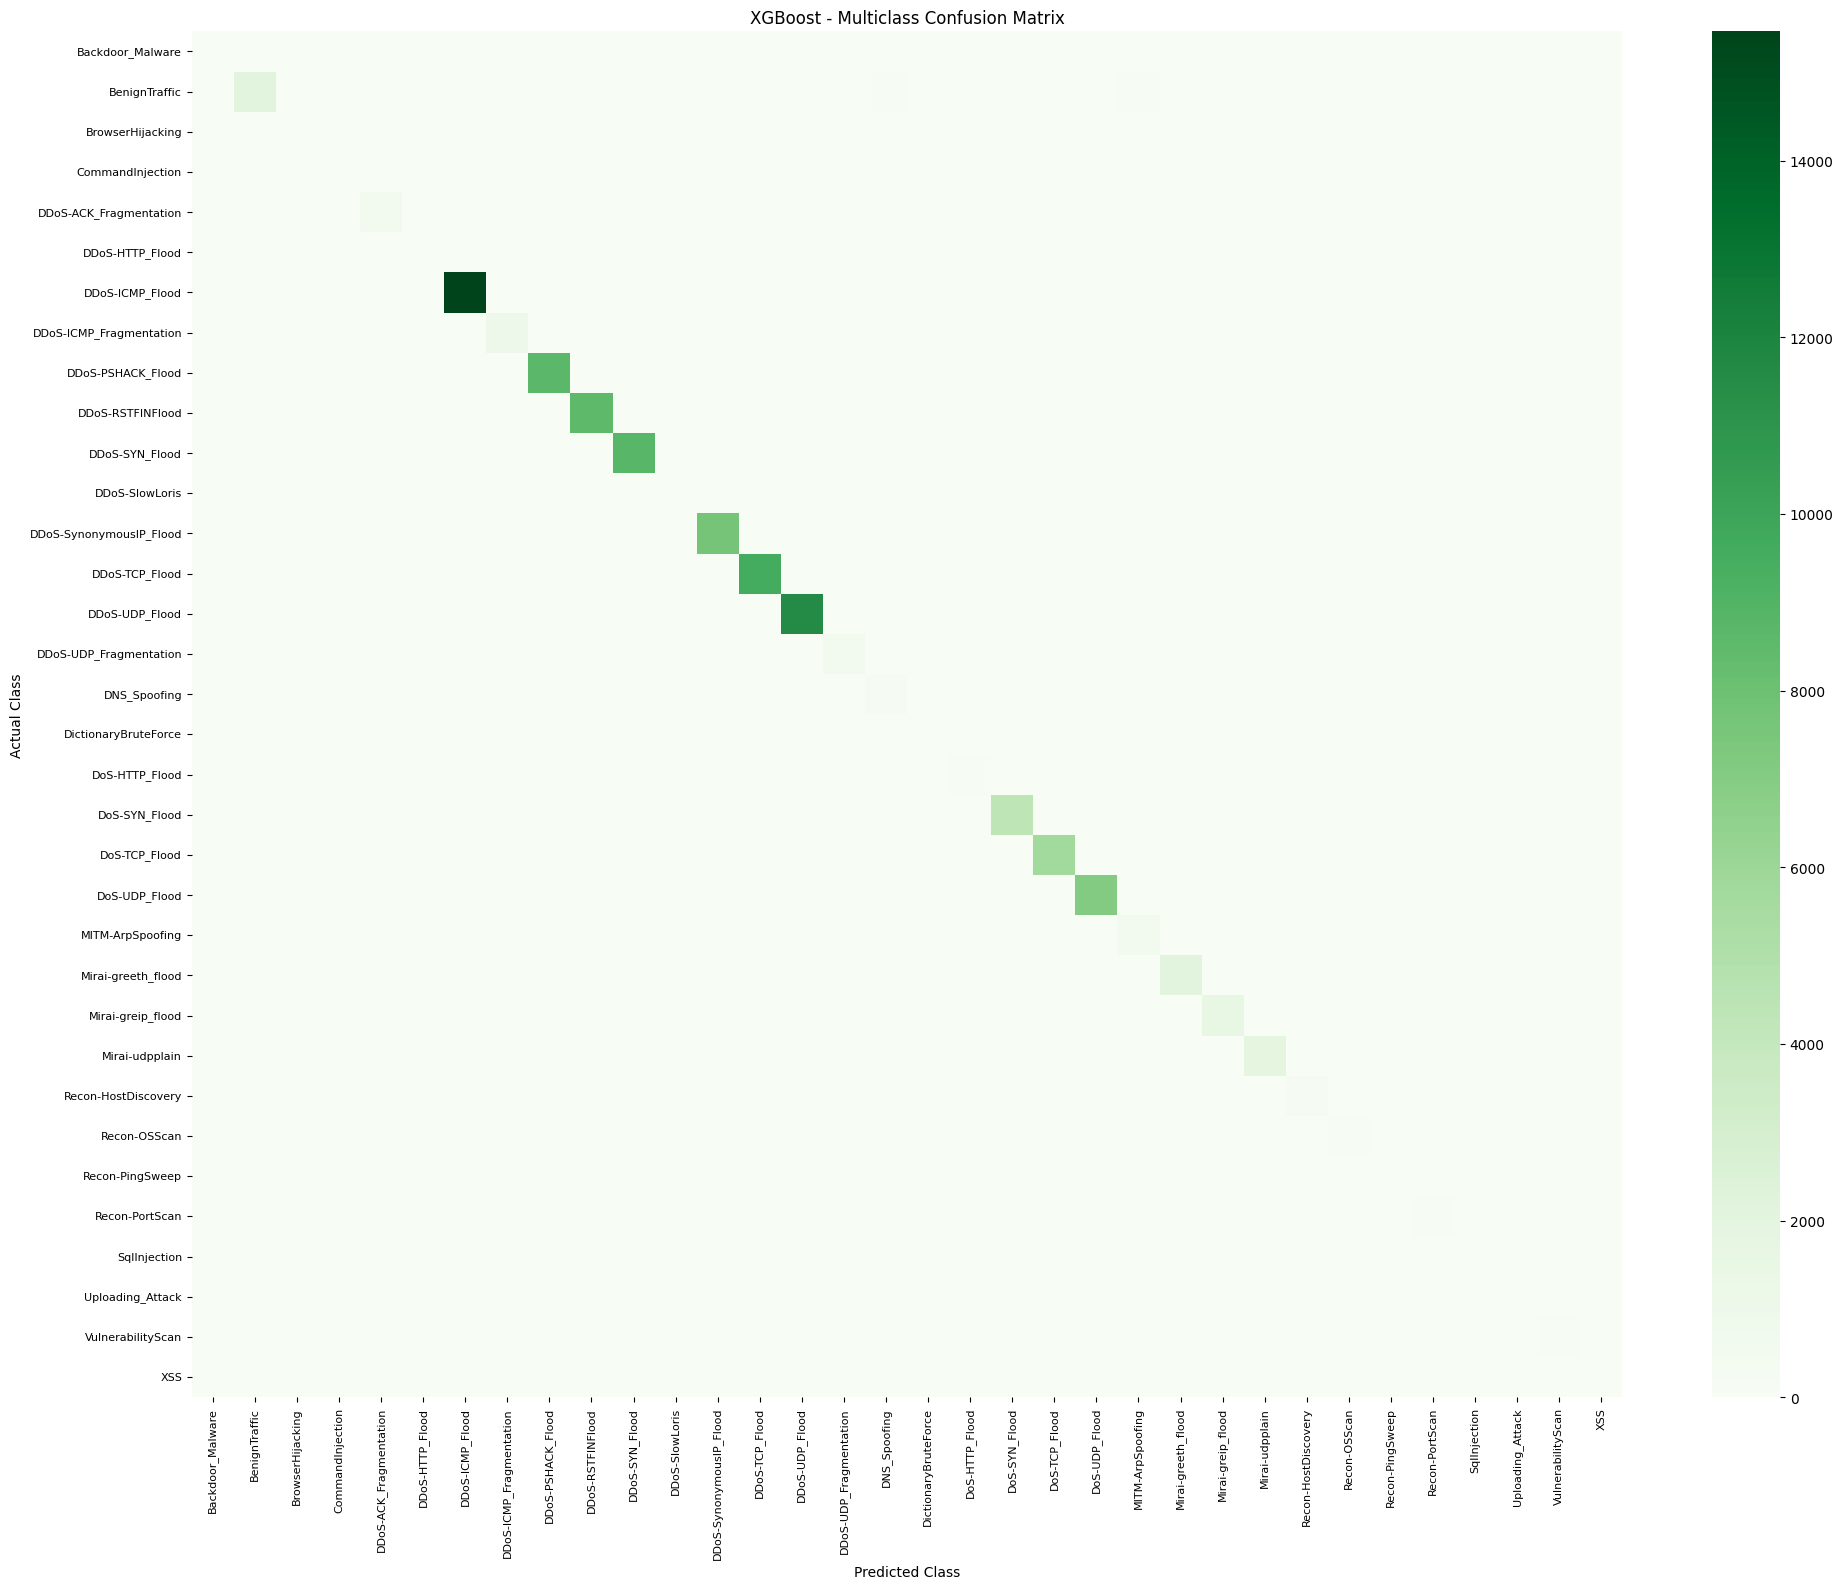

Confusion Matrix Shape: (34, 34)


In [52]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

xgb_confusion_matrix = confusion_matrix(
    y_test_multi_encoded,
    xgb_multi_predictions,
    labels=range(len(label_encoder_multi.classes_))
)

plt.figure(figsize=(20, 16))

sns.heatmap(
    xgb_confusion_matrix,
    annot=False,
    cmap="Greens",
    xticklabels=label_encoder_multi.classes_,
    yticklabels=label_encoder_multi.classes_
)

plt.title("XGBoost - Multiclass Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

print("Confusion Matrix Shape:", xgb_confusion_matrix.shape)


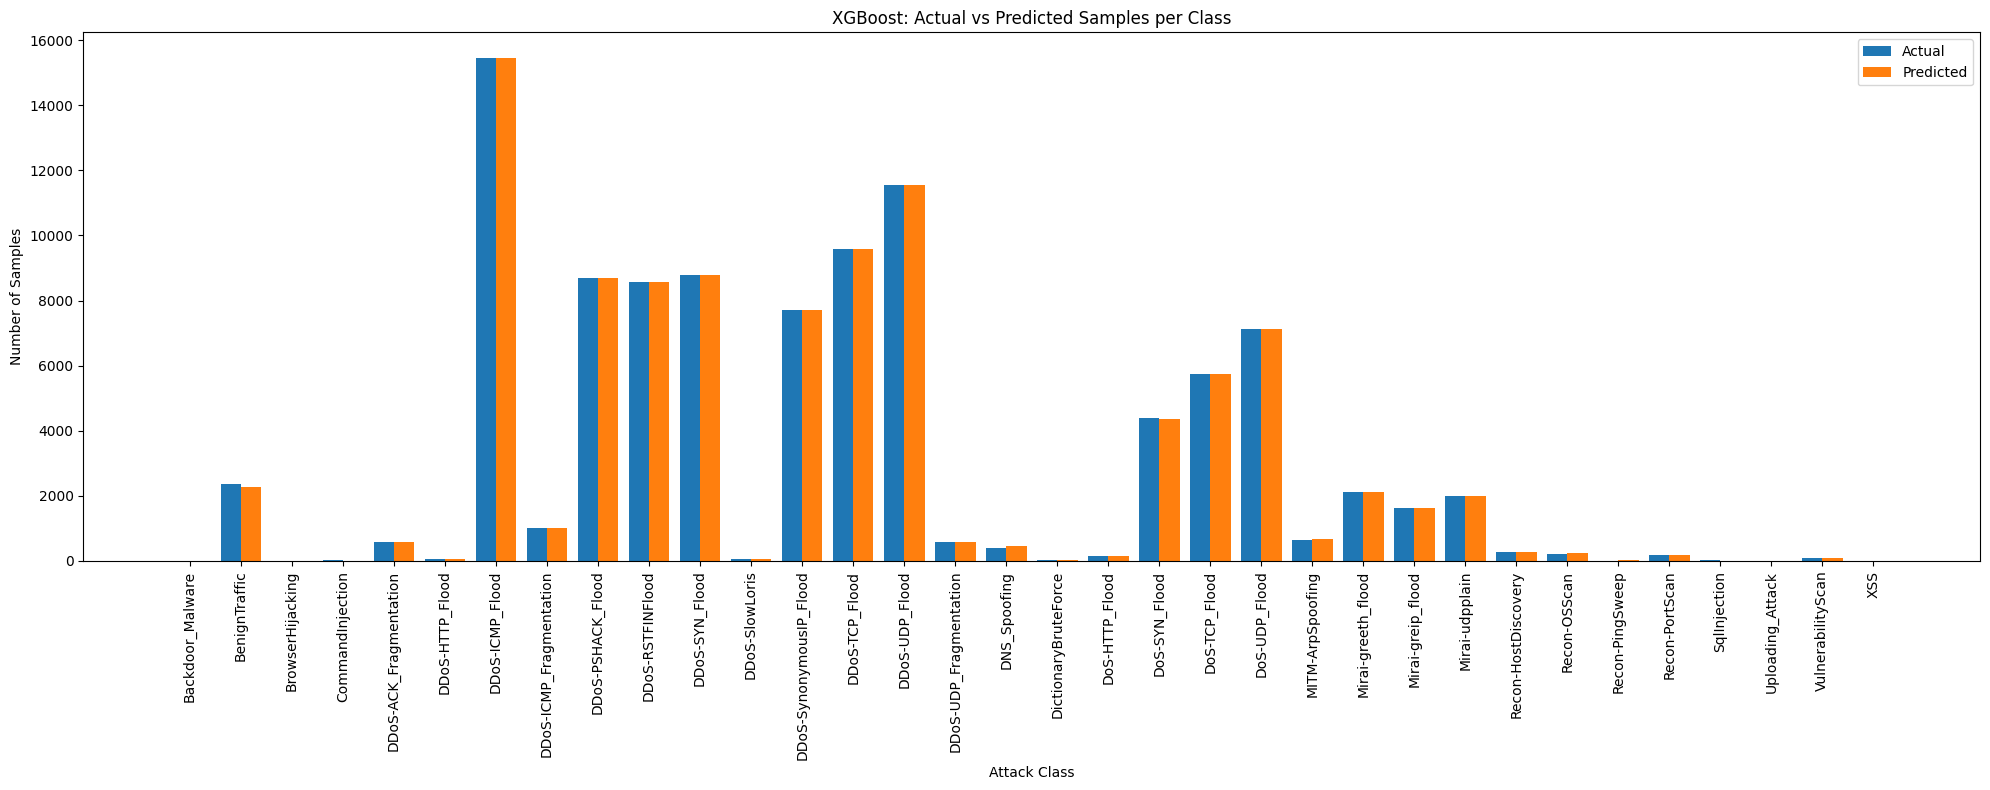

In [53]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

actual_counts = np.bincount(
    y_test_multi_encoded,
    minlength=len(label_encoder_multi.classes_)
)

predicted_counts = np.bincount(
    xgb_multi_predictions,
    minlength=len(label_encoder_multi.classes_)
)

xgb_comparison_df = pd.DataFrame({
    "Attack Class": label_encoder_multi.classes_,
    "Actual Samples": actual_counts,
    "Predicted Samples": predicted_counts
})

x = np.arange(len(xgb_comparison_df))
width = 0.4

plt.figure(figsize=(20, 8))

plt.bar(
    x - width / 2,
    xgb_comparison_df["Actual Samples"],
    width,
    label="Actual"
)

plt.bar(
    x + width / 2,
    xgb_comparison_df["Predicted Samples"],
    width,
    label="Predicted"
)

plt.title("XGBoost: Actual vs Predicted Samples per Class")
plt.xlabel("Attack Class")
plt.ylabel("Number of Samples")
plt.xticks(x, xgb_comparison_df["Attack Class"], rotation=90)
plt.legend()
plt.tight_layout()
plt.show()


**Final model comparison**

In [54]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test_multi_encoded, rf_multi_predictions),
        accuracy_score(y_test_multi_encoded, xgb_multi_predictions)
    ],
    "Macro Precision": [
        precision_score(
            y_test_multi_encoded, rf_multi_predictions,
            average="macro", zero_division=0
        ),
        precision_score(
            y_test_multi_encoded, xgb_multi_predictions,
            average="macro", zero_division=0
        )
    ],
    "Macro Recall": [
        recall_score(
            y_test_multi_encoded, rf_multi_predictions,
            average="macro", zero_division=0
        ),
        recall_score(
            y_test_multi_encoded, xgb_multi_predictions,
            average="macro", zero_division=0
        )
    ],
    "Macro F1-Score": [
        f1_score(
            y_test_multi_encoded, rf_multi_predictions,
            average="macro", zero_division=0
        ),
        f1_score(
            y_test_multi_encoded, xgb_multi_predictions,
            average="macro", zero_division=0
        )
    ]
})

display(model_comparison.round(4))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Random Forest,0.9899,0.7983,0.7326,0.7481
1,XGBoost,0.9921,0.8479,0.8088,0.8118


In [55]:

# Copy your existing results table
results_percentage = model_comparison.copy()

# Convert metric columns to percentages
for column in ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-Score"]:
    if column in results_percentage.columns:
        results_percentage[column] = (
            results_percentage[column] * 100
        ).round(2)

# Display results
display(results_percentage)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Random Forest,98.99,79.83,73.26,74.81
1,XGBoost,99.21,84.79,80.88,81.18


**Compare the models visually**

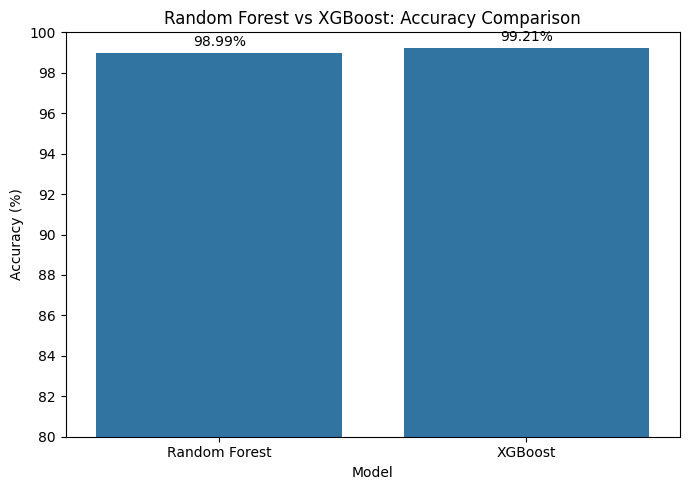

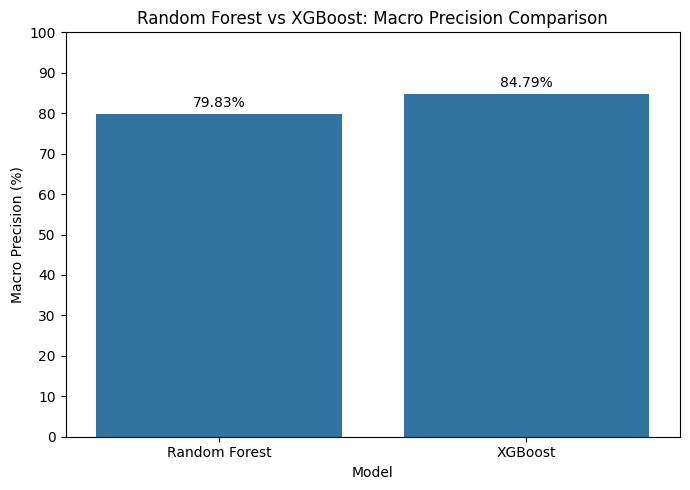

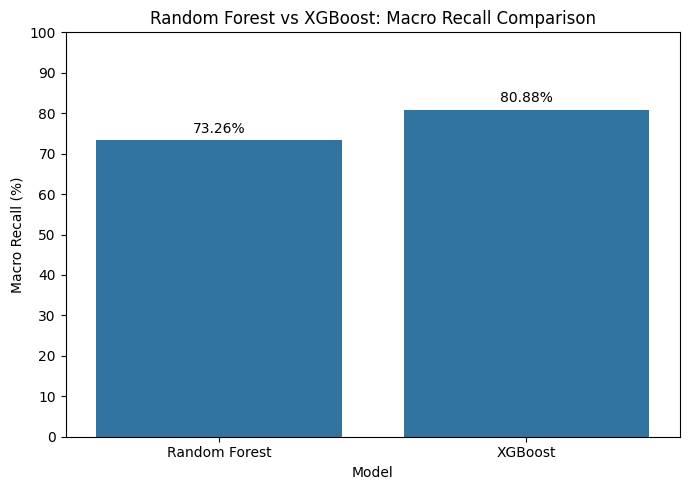

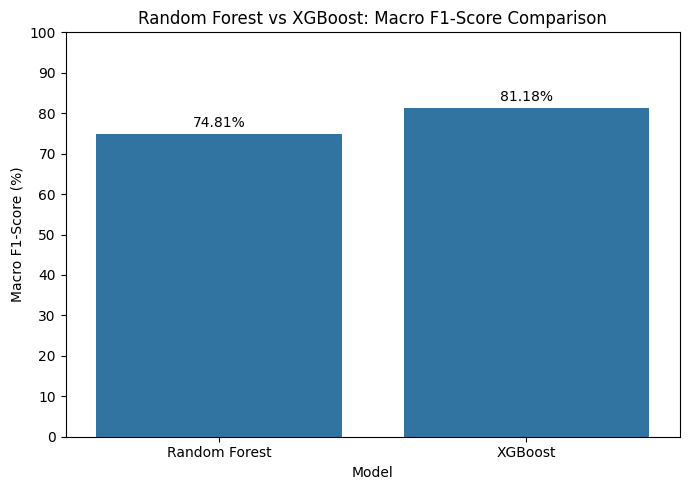

In [56]:

import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score"
]

for metric in metrics:

    plt.figure(figsize=(7, 5))

    ax = sns.barplot(
        data=results_percentage,
        x="Model",
        y=metric
    )

    # Add values above the bars
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f%%",
            padding=3
        )

    plt.title(f"Random Forest vs XGBoost: {metric} Comparison")
    plt.ylabel(f"{metric} (%)")
    plt.xlabel("Model")

    # Adjust the axis to show the full range if scores are below 80%
    min_value = results_percentage[metric].min()
    max_value = results_percentage[metric].max()

    if min_value >= 80:
        plt.ylim(80, min(100, max_value + 3))
        plt.yticks(range(80, 101, 2))
    else:
        plt.ylim(0, 100)
        plt.yticks(range(0, 101, 10))

    plt.tight_layout()
    plt.show()


**PKL File**

In [57]:

import pickle

# Combine both trained models and the label encoder
model_bundle = {
    "random_forest": rf_multi,
    "xgboost": xgb_multi,
    "label_encoder": label_encoder_multi,
    "feature_names": X_train_multi.columns.tolist()
}

# Save everything into one PKL file
with open("cic_iot_multiclass_models.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

print("Combined model file created successfully!")


Combined model file created successfully!


In [58]:
with open("label_encoder_multi.pkl", "wb") as file:
    pickle.dump(label_encoder_multi, file)

print("Label encoder saved successfully!")

Label encoder saved successfully!


In [59]:
from google.colab import files

files.download("cic_iot_multiclass_models.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
from google.colab import files

files.download("random_forest_multi.pkl")
files.download("xgboost_multi.pkl")
files.download("label_encoder_multi.pkl")

FileNotFoundError: Cannot find file: random_forest_multi.pkl